# Задание 4.11

$n$ лиц условились о встрече между 10 и 11 часами утра, причём договорились ждать друг друга не более $60\cdot q$ минут ($q<1$). Считая, что момент прихода на встречу выбирается каждым «наудачу» в пределах указанного часа, докажите, что вероятность того, что встреча состоится, определяется равенством

$$
P_n=nq^{n-1}-(n-1)q^n .
$$

Проверить формулу для $n=2$ и $n=3$. Для $n=3$ найти также вероятность того, что встреча по крайней мере двух лиц состоится.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Модель.** Время измеряем в часах от 10:00. Моменты прихода $t_1,\dots,t_n$ — независимые, равномерные на $[0,1]$; $\Omega=[0,1]^n$, $\mu(\Omega)=1$. Каждый ждёт не больше $q$, поэтому все $n$ человек встретятся, только если последний пришёл не позже, чем через $q$ после первого:

$$
M=\{\max_i t_i-\min_i t_i\le q\}.
$$

**Доказательство формулы.** Разобьём по тому, кто пришёл первым и когда. Минимум $m=\min t_i$ имеет плотность $n(1-m)^{n-1}$. Остальные $n-1$ моментов при условии $\min=m$ независимы и равномерны на $[m,1]$. Они должны попасть в $[m,\,m+q]$:

$$
\mathbb P(M\mid \min=m)=\Big(\frac{\min(q,\,1-m)}{1-m}\Big)^{n-1}.
$$

Отсюда

$$
P_n=\int_0^{1-q}n(1-m)^{n-1}\frac{q^{n-1}}{(1-m)^{n-1}}\,dm+\int_{1-q}^{1}n(1-m)^{n-1}\,dm=nq^{n-1}(1-q)+q^n=nq^{n-1}-(n-1)q^n .\qquad\blacksquare
$$

**Проверка.**
- $n=2$: $P_2=2q-q^2=1-(1-q)^2$ — квадрат минус два треугольника с катетом $1-q$ (как в задачах 4.6–4.7). При $q=\frac14$: $P_2=\frac{7}{16}$.
- $n=3$: $P_3=3q^2-2q^3$. При $q=\frac14$: $P_3=\frac{3}{16}-\frac{2}{64}=\frac{5}{32}=0{,}15625$.

**Встреча хотя бы двух лиц ($n=3$).** Противоположное событие: никакие двое не встретились, т.е. упорядоченные моменты $t_{(1)}<t_{(2)}<t_{(3)}$ отстоят друг от друга больше чем на $q$. Сдвиг $s_1=t_{(1)}$, $s_2=t_{(2)}-q$, $s_3=t_{(3)}-2q$ переводит это множество в упорядоченную тройку на $[0,1-2q]$ объёма $\frac{(1-2q)^3}{3!}$. Умножаем на $3!$ порядков прихода:

$$
\mathbb P(\text{встретятся хотя бы двое})=1-(1-2q)_+^3 ,
$$

где $(z)_+=\max(z,0)$. При $q\ge\frac12$ это 1. При $q=\frac14$: $1-\frac18=\frac78=0{,}875$.

**Моделирование:** берём $q=\frac14$ (15 минут) и проверяем формулы для всех $q$ на сетке.

n = 2: P_n = -q**2 + 2*q   (формула: -q**2 + 2*q)
n = 3: P_n = -2*q**3 + 3*q**2   (формула: -2*q**3 + 3*q**2)
n = 4: P_n = -3*q**4 + 4*q**3   (формула: -3*q**4 + 4*q**3)


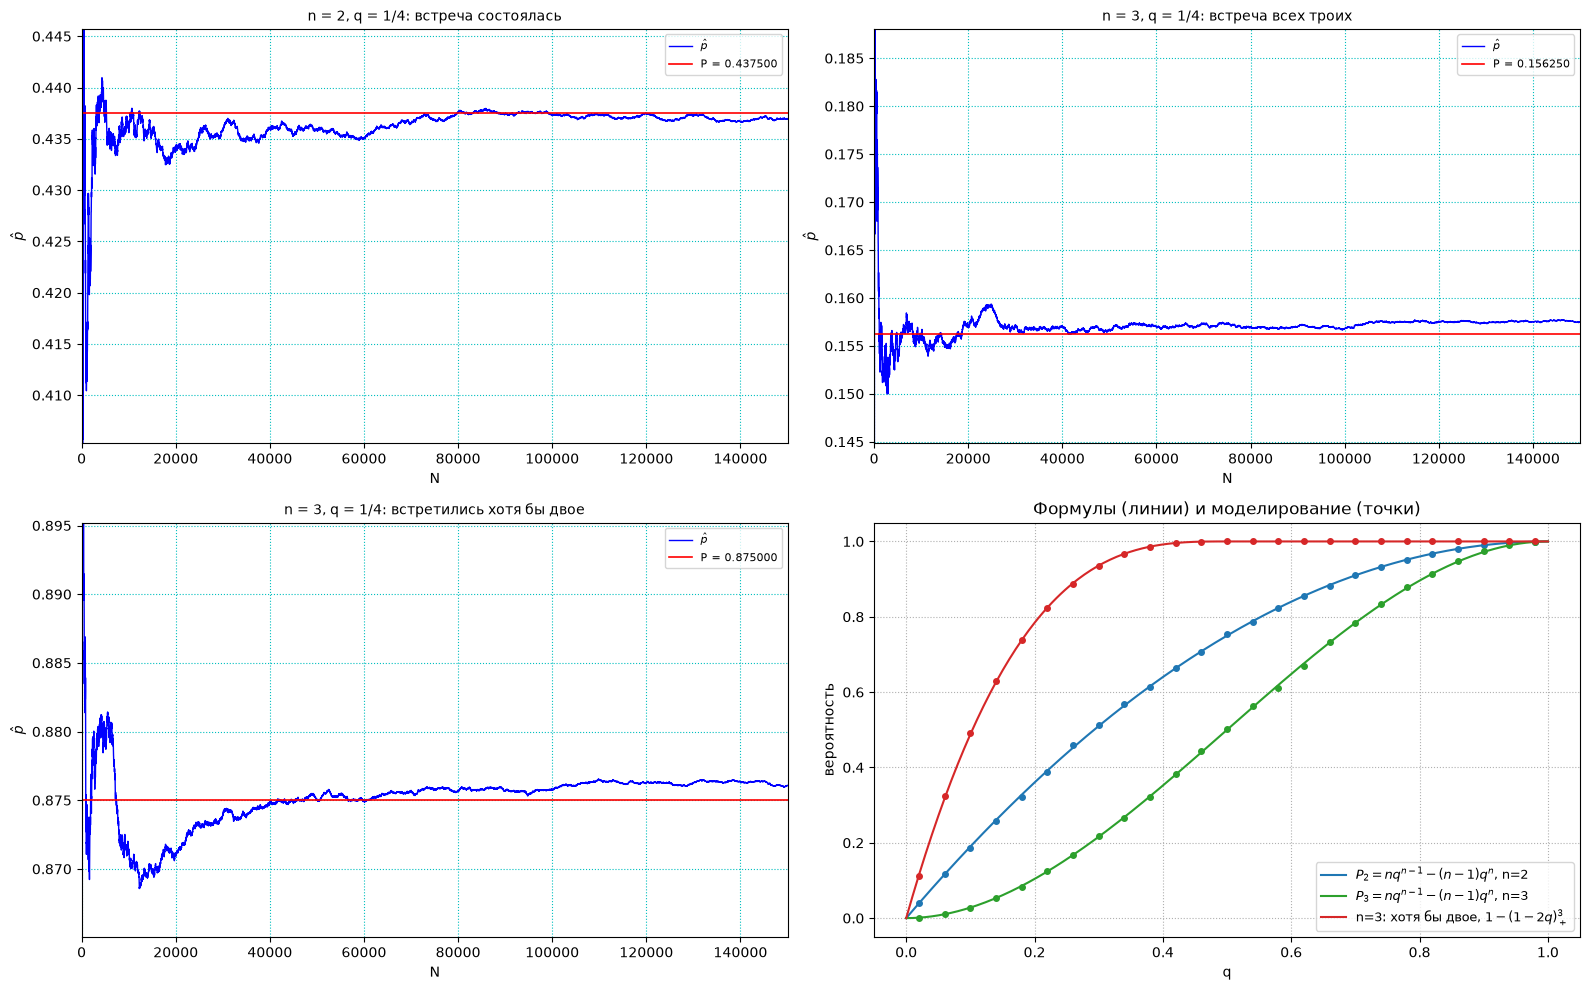

q = 1/4, N = 150000:
  n = 2: P_2 = 0.437500,  p̂ = 0.436953
  n = 3: P_3 = 0.156250,  p̂ = 0.157493
  n = 3, хотя бы двое: P = 0.875000,  p̂ = 0.876080


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Символьная проверка формулы P_n через интеграл по минимуму ----------
n_, q_, m_ = sp.symbols("n q m", positive=True)
for n in (2, 3, 4):
    Pn = sp.integrate(n*q_**(n - 1), (m_, 0, 1 - q_)) + sp.integrate(n*(1 - m_)**(n - 1), (m_, 1 - q_, 1))
    print(f"n = {n}: P_n = {sp.expand(Pn)}   (формула: {sp.expand(n*q_**(n - 1) - (n - 1)*q_**n)})")

P_meet = lambda n, q: n*q**(n - 1) - (n - 1)*q**n          # все n встретились
P_two = lambda q: 1 - np.clip(1 - 2*q, 0, None)**3        # n = 3: встретились хотя бы двое


def simulate(n, q, N):
    """Моделирование: N опытов, n лиц, ожидание q. Возвращает (все встретились, хоть двое встретились)."""
    t = rng.random((N, n))
    ts = np.sort(t, axis=1)
    all_meet = ts[:, -1] - ts[:, 0] <= q                  # последний пришёл не позже, чем через q после первого
    some_two = np.any(np.diff(ts, axis=1) <= q, axis=1)   # хотя бы два соседних прихода ближе q
    return all_meet, some_two


q, N = 0.25, 150_000
m2, _ = simulate(2, q, N)
m3, two3 = simulate(3, q, N)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
p2 = plot_freq(axes[0, 0], m2, P_meet(2, q), "n = 2, q = 1/4: встреча состоялась")
p3 = plot_freq(axes[0, 1], m3, P_meet(3, q), "n = 3, q = 1/4: встреча всех троих")
pt = plot_freq(axes[1, 0], two3, P_two(q), "n = 3, q = 1/4: встретились хотя бы двое")

# сравнение формул с моделированием для разных q
qs = np.linspace(0.02, 0.98, 25)
qq = np.linspace(0, 1, 300)
for n, c in ((2, "tab:blue"), (3, "tab:green")):
    axes[1, 1].plot(qq, P_meet(n, qq), color=c, label=f"$P_{n}=nq^{{n-1}}-(n-1)q^n$, n={n}")
    axes[1, 1].plot(qs, [simulate(n, qv, 20_000)[0].mean() for qv in qs], "o", color=c, ms=4)
axes[1, 1].plot(qq, P_two(qq), color="tab:red", label="n=3: хотя бы двое, $1-(1-2q)_+^3$")
axes[1, 1].plot(qs, [simulate(3, qv, 20_000)[1].mean() for qv in qs], "o", color="tab:red", ms=4)
axes[1, 1].set_xlabel("q"); axes[1, 1].set_ylabel("вероятность"); axes[1, 1].grid(ls=":")
axes[1, 1].set_title("Формулы (линии) и моделирование (точки)"); axes[1, 1].legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"q = 1/4, N = {N}:")
print(f"  n = 2: P_2 = {P_meet(2, q):.6f},  p̂ = {p2:.6f}")
print(f"  n = 3: P_3 = {P_meet(3, q):.6f},  p̂ = {p3:.6f}")
print(f"  n = 3, хотя бы двое: P = {P_two(q):.6f},  p̂ = {pt:.6f}")